📊 01. Análisis Exploratorio de Datos (EDA) - Segmentación de Clientes
Este documento contiene la estructura formal del notebook de análisis exploratorio para el proyecto de clasificación multiclase de clientes del sector automovilístico.

# 📊 01. Análisis Exploratorio Inicial (EDA) - Segmentación de Clientes
Este notebook recoge el análisis exploratorio inicial sobre el conjunto completo `data/Train.csv` (8,068 registros), con el objetivo de comprender la estructura general del dataset, el equilibrio de clases y la distribución de las variables antes de realizar la partición estratificada (`train_70`, `val_15`, `test_15`).

---

## 1. Carga de Datos e Infraestructura 📦
**Descripción:**  
Configuración del entorno de visualización (`seaborn` y `matplotlib`) y carga del archivo `data/Train.csv` desde el repositorio local (incluyendo descarga automática vía `kagglehub` como respaldo en caso de que el archivo no esté presente, y descartando `Test.csv` conforme a la decisión `D-006` del *Decision Log*).

In [14]:
import os
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

# Configuración del estilo visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Ruta local de Train.csv (descartamos Test.csv según decisión D-006)
os.makedirs('data', exist_ok=True)
ruta_train = "data/Train.csv"

# Comprobar si Train.csv ya existe en el repositorio; si no, descargarlo con kagglehub
if not os.path.exists(ruta_train):
    print("No se encontró data/Train.csv localmente. Descargando desde Kaggle...")
    path = kagglehub.dataset_download("kaushiksuresh147/customer-segmentation")
    shutil.copy(os.path.join(path, "Train.csv"), ruta_train)
    print("¡Descarga y copia completadas en data/Train.csv!")
else:
    print("El archivo data/Train.csv ya existe en el repositorio. Cargando localmente...")

# Cargar el dataset completo (8,068 registros)
train_df = pd.read_csv(ruta_train)

print(f"Dataset Train.csv listo: {train_df.shape[0]} filas y {train_df.shape[1]} columnas.")
train_df.head()

El archivo data/Train.csv ya existe en el repositorio. Cargando localmente...
Dataset Train.csv listo: 8068 filas y 11 columnas.


,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A


## 2. Inspección General y Diagnóstico de Nulos 🔎
**Descripción:**  
Diagnóstico descriptivo de las 8,068 observaciones de `Train.csv`. Se identifican los tipos de datos, la cardinalidad y el porcentaje de valores faltantes por columna como primera aproximación exploratoria (las decisiones de imputación se tomarán posteriormente sobre `train_70` tras el split para evitar fuga de datos).

In [15]:
# Resumen único de tipos, valores nulos y cardinalidad
info_df = pd.DataFrame({
    'Tipo': train_df.dtypes,
    'Valores Nulos': train_df.isnull().sum(),
    '% Nulos': (train_df.isnull().sum() / len(train_df) * 100).round(2),
    'Valores Únicos': train_df.nunique()
})

print("--- RESUMEN DE VARIABLES EN TRAIN.CSV ---")
display(info_df)

print("\n--- ESTADÍSTICOS DESCRIPTIVOS (NUMÉRICAS) ---")
display(train_df.drop(columns=['ID']).describe().round(2))

--- RESUMEN DE VARIABLES EN TRAIN.CSV ---


,Tipo,Valores Nulos,% Nulos,Valores Únicos
ID,int64,0,0.00,8068
Gender,str,0,0.00,2
Ever_Married,str,140,1.74,2
Age,int64,0,0.00,67
Graduated,str,78,0.97,2
Profession,str,124,1.54,9
Work_Experience,float64,829,10.28,15
Spending_Score,str,0,0.00,3
Family_Size,float64,335,4.15,9
Var_1,str,76,0.94,7



--- ESTADÍSTICOS DESCRIPTIVOS (NUMÉRICAS) ---


,Age,Work_Experience,Family_Size
count,8068.00,7239.00,7733.00
mean,43.47,2.64,2.85
std,16.71,3.41,1.53
min,18.00,0.00,1.00
25%,30.00,0.00,2.00
50%,40.00,1.00,3.00
75%,53.00,4.00,4.00
max,89.00,14.00,9.00


## 3. Análisis Univariado (Distribución de Variables) 📈
**Descripción:**  
Exploración visual de la variable objetivo (`Segmentation`) y de las variables numéricas (`Age`, `Work_Experience`, `Family_Size`) sobre `Train.csv` para observar el balanceo entre categorías y la forma de las distribuciones.  

> **Siguiente paso:** A partir de esta exploración inicial, el siguiente hito será generar la partición estratificada **70/15/15** (`train_70.csv`, `val_15.csv` y `test_15.csv`, evitando nombres que colisionen con `Test.csv` en sistemas macOS/Windows) y realizar el análisis profundo y definición de reglas de imputación exclusivamente sobre `train_70`.

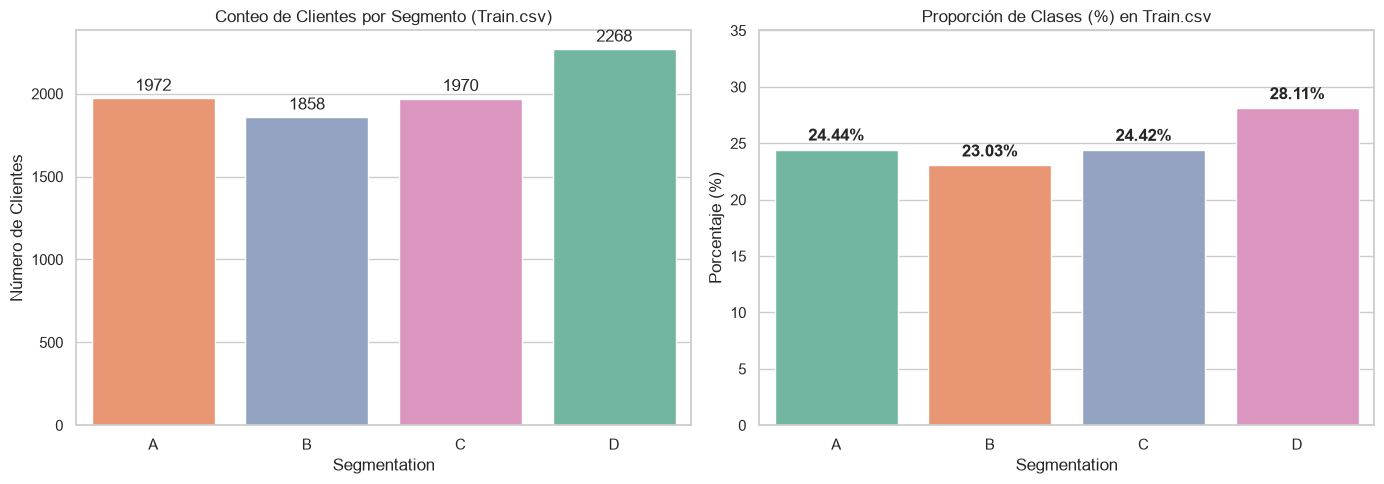

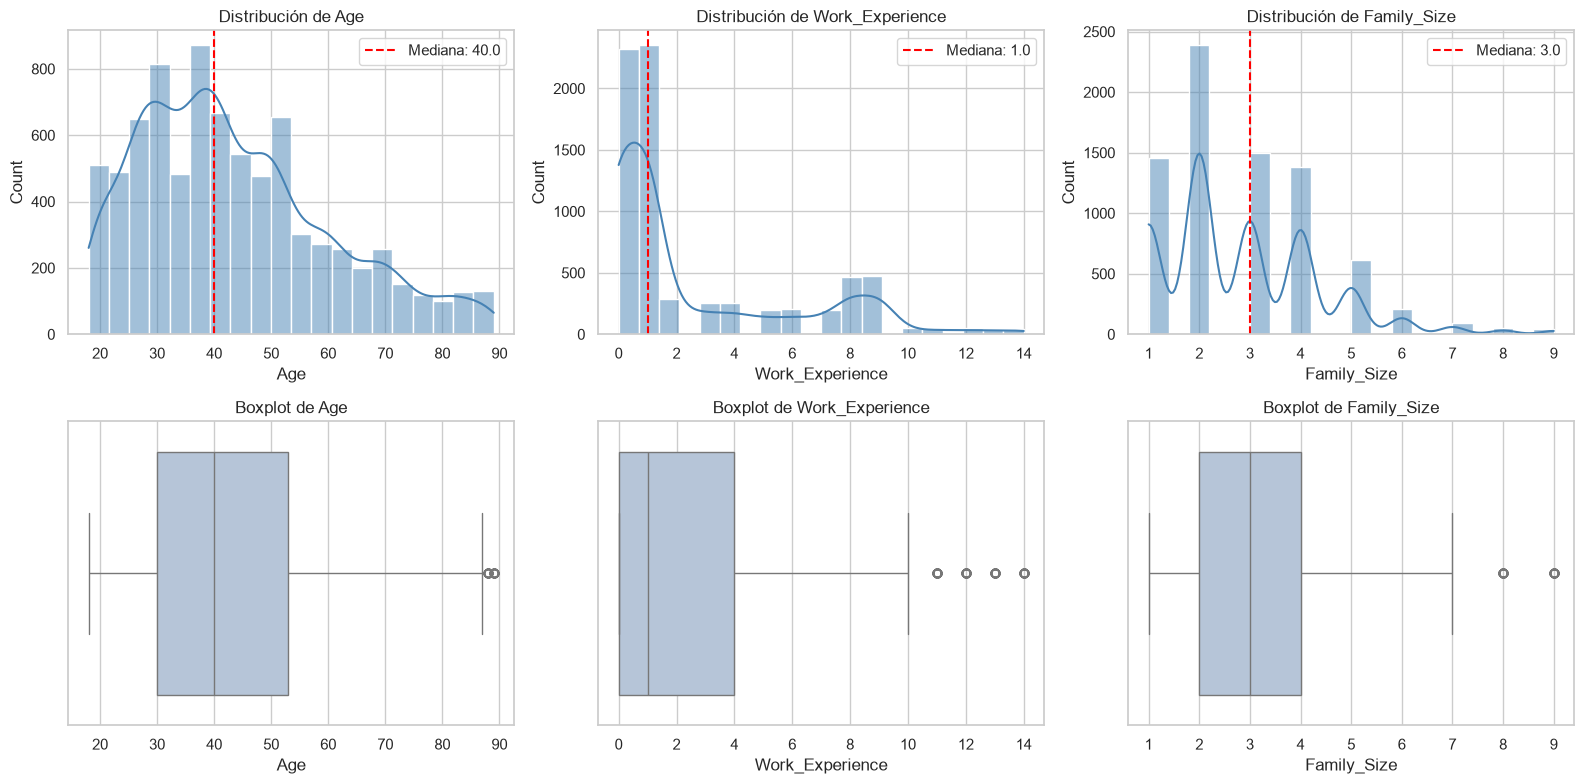

In [16]:
# 1. Distribución de la variable objetivo (Segmentation)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order_seg = ['A', 'B', 'C', 'D']

sns.countplot(
    data=train_df, x='Segmentation', order=order_seg,
    ax=axes[0], palette='Set2', hue='Segmentation', legend=False
)
axes[0].set_title('Conteo de Clientes por Segmento (Train.csv)')
axes[0].set_ylabel('Número de Clientes')
for container in axes[0].containers:
    axes[0].bar_label(container, padding=3)

seg_pct = train_df['Segmentation'].value_counts(normalize=True).reindex(order_seg) * 100
sns.barplot(
    x=seg_pct.index, y=seg_pct.values,
    ax=axes[1], palette='Set2', hue=seg_pct.index, legend=False
)
axes[1].set_title('Proporción de Clases (%) en Train.csv')
axes[1].set_ylabel('Porcentaje (%)')
axes[1].set_ylim(0, 35)
for i, v in enumerate(seg_pct.values):
    axes[1].text(i, v + 0.8, f"{v:.2f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# 2. Distribución de variables numéricas (Histogramas + Boxplots)
num_cols = ['Age', 'Work_Experience', 'Family_Size']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for i, col in enumerate(num_cols):
    sns.histplot(train_df[col].dropna(), kde=True, ax=axes[0, i], color='steelblue', bins=20)
    axes[0, i].axvline(train_df[col].median(), color='red', linestyle='--', label=f"Mediana: {train_df[col].median():.1f}")
    axes[0, i].set_title(f'Distribución de {col}')
    axes[0, i].legend()
    
    sns.boxplot(x=train_df[col].dropna(), ax=axes[1, i], color='lightsteelblue')
    axes[1, i].set_title(f'Boxplot de {col}')

plt.tight_layout()
plt.show()

## 4. Generación del Split Estratificado (`train_70`, `val_15`, `test_15`) ✂️
**Descripción:**  
Una vez completada la exploración inicial sobre `Train.csv` (8,068 registros), se ejecuta una única partición estratificada por `Segmentation` (`random_state=42`) en proporción **70% Train (`5,647` filas) / 15% Validation (`1,210` filas) / 15% Test (`1,211` filas)**.  

Los tres archivos se exportan en `data/` **conservando sus valores nulos intactos** (para ser procesados posteriormente dentro del `Pipeline` en `src/`) y con nombres diferenciados (`train_70.csv`, `val_15.csv`, `test_15.csv`) para evitar colisiones de mayúsculas/minúsculas con `Test.csv` en sistemas macOS/Windows (decisión `D-006`).

In [17]:
from sklearn.model_selection import train_test_split

ruta_train_70 = "data/train_70.csv"
ruta_val_15 = "data/val_15.csv"
ruta_test_15 = "data/test_15.csv"

# Generar y guardar el split estratificado 70/15/15 con nulos intactos
if not (os.path.exists(ruta_train_70) and os.path.exists(ruta_val_15) and os.path.exists(ruta_test_15)):
    train_70, temp_df = train_test_split(
        train_df, test_size=0.30, random_state=42, stratify=train_df['Segmentation']
    )
    val_15, test_15 = train_test_split(
        temp_df, test_size=0.50, random_state=42, stratify=temp_df['Segmentation']
    )
    
    train_70.to_csv(ruta_train_70, index=False)
    val_15.to_csv(ruta_val_15, index=False)
    test_15.to_csv(ruta_test_15, index=False)
    print("¡Partición 70/15/15 generada y guardada en data/ con nulos intactos!")
else:
    print("Los archivos train_70.csv, val_15.csv y test_15.csv ya existen en data/.")

# Comprobación final de tamaños, nulos intactos y proporciones de clase
for nombre, ruta in [('train_70', ruta_train_70), ('val_15', ruta_val_15), ('test_15', ruta_test_15)]:
    df_check = pd.read_csv(ruta)
    dist = (df_check['Segmentation'].value_counts(normalize=True).reindex(['A', 'B', 'C', 'D']) * 100).round(2).to_dict()
    print(f"{nombre}: {df_check.shape[0]} filas | Nulos totales: {df_check.isnull().sum().sum()} | Clases (%): {dist}")

Los archivos train_70.csv, val_15.csv y test_15.csv ya existen en data/.
train_70: 5647 filas | Nulos totales: 1098 | Clases (%): {'A': 24.44, 'B': 23.04, 'C': 24.42, 'D': 28.1}
val_15: 1210 filas | Nulos totales: 240 | Clases (%): {'A': 24.46, 'B': 23.06, 'C': 24.38, 'D': 28.1}
test_15: 1211 filas | Nulos totales: 244 | Clases (%): {'A': 24.44, 'B': 22.96, 'C': 24.44, 'D': 28.16}
